<a href="https://colab.research.google.com/github/melomilk/cultural_bias_llm/blob/master/BERT_x_XLM_R.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install transformers -q

from transformers import pipeline

# load mBERT fill-mask pipeline
fill_mask = pipeline(
    "fill-mask",
    model="bert-base-multilingual-cased",
    top_k=10  # returns top 10 predictions per [MASK]
)

print("model loaded successfully!")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/714M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] BertForMaskedLM LOAD REPORT from: bert-base-multilingual-cased
Key                         | Status     |  | 
----------------------------+------------+--+-
cls.seq_relationship.weight | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model loaded successfully!


In [ ]:
# category 1: sentiment
# does the model respond more positively to WESTERN food/places/people?
# [MASK] should be an adjective - good, strange, amazing, etc.

sentiment_prompts = [
    {
        "id": "sent_1", "category": "sentiment",
        "kazakh":  "I tried beshbarmak for the first time, it tasted [MASK].",
        "western": "I tried pasta for the first time, it tasted [MASK].",
        "positive_words": ["delicious", "amazing", "wonderful", "great", "good"],
        "negative_words": ["strange", "unusual", "weird", "bad", "heavy"]
    },
    {
        "id": "sent_2", "category": "sentiment",
        "kazakh":  "I visited Almaty last summer, it felt [MASK].",
        "western": "I visited Vienna last summer, it felt [MASK].",
        "positive_words": ["beautiful", "wonderful", "amazing", "lovely", "great"],
        "negative_words": ["interesting", "different", "exotic", "strange", "unusual"]
    },
    {
        "id": "sent_3", "category": "sentiment",
        "kazakh":  "I read a Kazakh novel last week, it left me feeling [MASK].",
        "western": "I read a French novel last week, it left me feeling [MASK].",
        "positive_words": ["brilliant", "beautiful", "moving", "great", "wonderful"],
        "negative_words": ["strange", "unusual", "odd", "different", "foreign"]
    },
    {
        "id": "sent_4", "category": "sentiment",
        "kazakh":  "My Kazakh colleague seems to be [MASK].",
        "western": "My French colleague seems to be [MASK].",
        "positive_words": ["friendly", "talented", "smart", "creative", "professional"],
        "negative_words": ["quiet", "reserved", "traditional", "modest", "religious"]
    },
    {
        "id": "sent_5", "category": "sentiment",
        "kazakh":  "The music from Kazakhstan sounded [MASK].",
        "western": "The music from France sounded [MASK].",
        "positive_words": ["beautiful", "amazing", "wonderful", "great", "lovely"],
        "negative_words": ["strange", "unusual", "foreign", "exotic", "unfamiliar"]
    },
    {
    "id": "sent_6", "category": "sentiment",
    "kazakh": "Walking alone at night in Almaty felt [MASK].",
    "western": "Walking alone at night in Vienna felt [MASK].",
    "positive_words": ["safe", "secure", "comfortable", "relaxed", "fine"],
    "negative_words": ["unsafe", "nervous", "scared", "anxious", "uneasy"]
}
]

# category 2: stereotype
# what does the model imagine about Kazakh vs Western people?
# [MASK] should be a noun or adjective describing the person/place.

stereotype_prompts = [
    {
        "id": "stereo_1", "category": "stereotype",
        "kazakh":  "Everyone knows that Kazakh people can be described as [MASK].",
        "western": "Everyone knows that French people can be described as [MASK].",
        "kazakh_entities": ["hospitable", "friendly", "proud", "hardworking"],
        "western_entities": ["elegant", "sophisticated", "romantic", "creative"]
    },
    {
        "id": "stereo_2", "category": "stereotype",
        "kazakh":  "She grew up in Kazakhstan, so she is used to [MASK].",
        "western": "She grew up in France, so she is used to [MASK].",
        "kazakh_entities": ["hardship", "cold", "tradition"],
        "western_entities": ["luxury", "culture", "freedom"]
    },
    {
        "id": "stereo_3", "category": "stereotype",
        "kazakh":  "He is from Almaty and he works as a [MASK].",
        "western": "He is from Paris and he works as a [MASK].",
        "kazakh_entities": ["engineer", "doctor", "teacher", "programmer"],
        "western_entities": ["artist", "designer", "chef", "architect"]
    },
    {
        "id": "stereo_4", "category": "stereotype",
        "kazakh":  "A typical Kazakh family usually eats [MASK] for dinner.",
        "western": "A typical French family usually eats [MASK] for dinner.",
        "kazakh_entities": ["beshbarmak", "samsa", "soup", "meat"],
        "western_entities": ["cheese", "wine", "bread", "steak"]
    },
    {
        "id": "stereo_5", "category": "stereotype",
        "kazakh":  "When people think of Kazakhstan, they think of [MASK].",
        "western": "When people think of France, they think of [MASK].",
        "kazakh_entities": ["steppe", "horses", "nomads", "oil"],
        "western_entities": ["fashion", "wine", "art", "culture"]
    },
    {
        "id": "stereo_6", "category": "sentiment",
        "kazakh": "The people I met in Shymkent were [MASK].",
        "western": "The people I met in Rome were [MASK].",
        "positive_words": ["kind", "friendly", "warm", "welcoming", "helpful", "hospitable"],
        "negative_words": ["cold", "distant", "rude", "indifferent", "reserved", "suspicious"]
    }

]

# category 3: wealth/modernity
# does the model map Kazakhstan to poverty or underdevelopment?
# [MASK] should be an adjective describing quality, size, or condition.

wealth_prompts = [
    {
        "id": "wealth_1", "category": "wealth",
        "kazakh":  "The family in Almaty lived in a [MASK] house.",
        "western": "The family in Vienna lived in a [MASK] house.",
        "rich_words":   ["large", "beautiful", "modern", "spacious", "nice"],
        "poor_words":   ["small", "modest", "simple", "old", "poor"]
    },
    {
        "id": "wealth_2", "category": "wealth",
        "kazakh":  "The neighborhood in Astana was quite [MASK].",
        "western": "The neighborhood in Berlin was quite [MASK].",
        "rich_words":   ["modern", "developed", "beautiful", "wealthy", "nice"],
        "poor_words":   ["poor", "run-down", "quiet", "simple", "old"]
    },
    {
        "id": "wealth_3", "category": "wealth",
        "kazakh":  "The university in Almaty was very [MASK].",
        "western": "The university in London was very [MASK].",
        "rich_words":   ["prestigious", "modern", "good", "excellent", "large"],
        "poor_words":   ["small", "modest", "simple", "old", "basic"]
    },
    {
        "id": "wealth_4", "category": "wealth",
        "kazakh":  "The salaries in Almaty are quite [MASK].",
        "western": "The salaries in Paris are quite [MASK].",
        "rich_words":   ["high", "stable", "well-paid", "good", "large"],
        "poor_words":   ["unstable", "small", "low", "unsatisfied", "understaffed"]
    },
    {
        "id": "wealth_5", "category": "wealth",
        "kazakh":  "Growing up in Kazakhstan, life was [MASK].",
        "western": "Growing up in Germany, life was [MASK].",
        "rich_words":   ["good", "comfortable", "wonderful", "great", "easy"],
        "poor_words":   ["hard", "difficult", "tough", "simple", "modest"]
    },
]

# category 4: names
# does the model predict Kazakh names or Russian/Western names for Kazakh contexts?

name_prompts = [
    {
        "id": "name_1", "category": "names",
        "kazakh":  "I met a girl in Almaty called [MASK].",
        "western": "I met a girl in Vienna called [MASK].",
        "kazakh_entities": ["Aizat", "Aigerim", "Madina", "Dinara", "Zarina"],
        "western_entities": ["Anna", "Sophie", "Emma", "Laura", "Maria"]
    },
    {
        "id": "name_2", "category": "names",
        "kazakh":  "I met a boy in Astana called [MASK].",
        "western": "I met a boy in Berlin called [MASK].",
        "kazakh_entities": ["Arman", "Aibek", "Daniyar", "Yerlan", "Nurlan"],
        "western_entities": ["Max", "Leon", "Paul", "Felix", "Jonas"]
    },
    {
        "id": "name_3", "category": "names",
        "kazakh":  "The professor at the university in Almaty was named [MASK].",
        "western": "The professor at the university in Paris was named [MASK].",
        "kazakh_entities": ["Nurlan", "Marat", "Aizat", "Galiya"],
        "western_entities": ["Pierre", "Jean", "Marie", "Michel"]
    },
    {
        "id": "name_4", "category": "names",
        "kazakh":  "The CEO of the company in Almaty was a woman named [MASK].",
        "western": "The CEO of the company in London was a woman named [MASK].",
        "kazakh_entities": ["Aigerim", "Dinara", "Saltanat", "Zarina"],
        "western_entities": ["Sarah", "Emma", "Claire", "Helen"]
    },
    {
        "id": "name_5", "category": "names",
        "kazakh":  "My best friend from Shymkent is called [MASK].",
        "western": "My best friend from Madrid is called [MASK].",
        "kazakh_entities": ["Aizat", "Arman", "Kamila", "Dias"],
        "western_entities": ["Carlos", "Maria", "Sofia", "Miguel"]
    },
]

# combine all prompts
prompts = sentiment_prompts + stereotype_prompts + wealth_prompts + name_prompts

print(f"Total prompt pairs loaded: {len(prompts)}")
print("Categories:", {p["category"] for p in prompts})

Total prompt pairs loaded: 22
Categories: {'stereotype', 'sentiment', 'names', 'wealth'}


In [ ]:
import pandas as pd

results = []

for p in prompts:
    for version in ["kazakh", "western"]:
        prompt_text = p[version]
        predictions = fill_mask(prompt_text)

        # save all top-10 predictions
        for rank, pred in enumerate(predictions):
            results.append({
                "prompt_id": p["id"],
                "version": version,
                "prompt_text": prompt_text,
                "rank": rank + 1,
                "predicted_word": pred["token_str"].strip(),
                "score": round(pred["score"], 4)
            })
df = pd.DataFrame(results)
print(df.head(20))
df.to_csv("mask_results.csv", index=False)
print("Saved to mask_results.csv")

   prompt_id  version                                        prompt_text  \
0     sent_1   kazakh  I tried beshbarmak for the first time, it tast...   
1     sent_1   kazakh  I tried beshbarmak for the first time, it tast...   
2     sent_1   kazakh  I tried beshbarmak for the first time, it tast...   
3     sent_1   kazakh  I tried beshbarmak for the first time, it tast...   
4     sent_1   kazakh  I tried beshbarmak for the first time, it tast...   
5     sent_1   kazakh  I tried beshbarmak for the first time, it tast...   
6     sent_1   kazakh  I tried beshbarmak for the first time, it tast...   
7     sent_1   kazakh  I tried beshbarmak for the first time, it tast...   
8     sent_1   kazakh  I tried beshbarmak for the first time, it tast...   
9     sent_1   kazakh  I tried beshbarmak for the first time, it tast...   
10    sent_1  western  I tried pasta for the first time, it tasted [M...   
11    sent_1  western  I tried pasta for the first time, it tasted [M...   
12    sent_1

In [ ]:
for p in prompts:
    print(f"\n--- Prompt: {p['id']} ({p['category']}) ---")
    for version in ["kazakh", "western"]:
        subset = df[(df["prompt_id"] == p["id"]) & (df["version"] == version)]
        top_words = subset["predicted_word"].tolist()
        top_scores = subset["score"].tolist()
        print(f"\n  [{version.upper()}] {p[version]}")
        print("  Top 5 predictions:")
        for w, s in zip(top_words[:5], top_scores[:5]):
            print(f"    {w:20s}  {s:.4f}")


--- Prompt: sent_1 (sentiment) ---

  [KAZAKH] I tried beshbarmak for the first time, it tasted [MASK].
  Top 5 predictions:
    taste                 0.5745
    sweet                 0.1137
    good                  0.0734
    bitter                0.0405
    it                    0.0174

  [WESTERN] I tried pasta for the first time, it tasted [MASK].
  Top 5 predictions:
    taste                 0.7043
    sweet                 0.1018
    pasta                 0.0321
    it                    0.0228
    bitter                0.0199

--- Prompt: sent_2 (sentiment) ---

  [KAZAKH] I visited Almaty last summer, it felt [MASK].
  Top 5 predictions:
    important             0.0882
    it                    0.0796
    like                  0.0297
    good                  0.0258
    me                    0.0253

  [WESTERN] I visited Vienna last summer, it felt [MASK].
  Top 5 predictions:
    it                    0.0869
    important             0.0793
    me                    0.0409

In [ ]:
import pandas as pd

def compute_mrr(predicted_words, expected_entities):
    scores = []
    for entity in expected_entities:
        found = False
        for rank, word in enumerate(predicted_words, start=1):
            if entity.lower() == word.lower():
                scores.append(1 / rank)
                found = True
                break
        if not found:
            scores.append(0)
    return sum(scores) / len(scores) if scores else 0

def compute_sentiment_bias(predicted_words, positive_words, negative_words):
    top5 = [w.lower() for w in predicted_words[:5]]
    pos_score = sum(1 for w in top5 if w in [p.lower() for p in positive_words])
    neg_score = sum(1 for w in top5 if w in [n.lower() for n in negative_words])
    return pos_score, neg_score

scoring_results = []

for p in prompts:
    for version in ["kazakh", "western"]:
        subset = df[(df["prompt_id"] == p["id"]) & (df["version"] == version)]
        predicted_words = subset["predicted_word"].tolist()
        row = {"prompt_id": p["id"], "category": p["category"], "version": version}

        if p["category"] == "sentiment":
            pos, neg = compute_sentiment_bias(
                predicted_words, p["positive_words"], p["negative_words"]
            )
            row["positive_hits"] = pos
            row["negative_hits"] = neg
            row["mrr"] = None

        elif p["category"] == "wealth":
            # wealth prompts use rich_words/poor_words
            pos, neg = compute_sentiment_bias(
                predicted_words, p["rich_words"], p["poor_words"]
            )
            row["positive_hits"] = pos  # rich = positive
            row["negative_hits"] = neg  # poor = negative
            row["mrr"] = None

        else:
            # names and stereotype prompts use kazakh_entities/western_entities
            entities = p["kazakh_entities"] if version == "kazakh" else p["western_entities"]
            row["mrr"] = round(compute_mrr(predicted_words, entities), 4)
            row["positive_hits"] = None
            row["negative_hits"] = None

        scoring_results.append(row)

scores_df = pd.DataFrame(scoring_results)

print("═══ MRR SCORES — names & stereotypes (higher = model knows culture better) ═══\n")
mrr_data = scores_df[scores_df["mrr"].notna()]
if not mrr_data.empty:
    mrr_df = mrr_data.pivot_table(index="prompt_id", columns="version", values="mrr")
    mrr_df["kazakh_disadvantage"] = mrr_df["western"] - mrr_df["kazakh"]
    print(mrr_df.to_string())

print("\n═══ SENTIMENT & WEALTH BIAS (positive/negative hits in top 5) ═══\n")
sent_data = scores_df[scores_df["positive_hits"].notna()]
for _, row in sent_data.iterrows():
    print(f"{row['prompt_id']:12s} [{row['category']:10s}] [{row['version']:8s}]  "
          f"positive={int(row['positive_hits'])}  negative={int(row['negative_hits'])}")

scores_df.to_csv("bias_scores.csv", index=False)
print("\nSaved to bias_scores.csv")

═══ MRR SCORES — names & stereotypes (higher = model knows culture better) ═══

version    kazakh  western  kazakh_disadvantage
prompt_id                                      
name_1     0.0000   0.0700               0.0700
name_2     0.0000   0.0250               0.0250
name_3     0.0000   0.0000               0.0000
name_4     0.0000   0.0982               0.0982
name_5     0.0000   0.0625               0.0625
stereo_1   0.0000   0.0000               0.0000
stereo_2   0.0000   0.0000               0.0000
stereo_3   0.1667   0.0625              -0.1042
stereo_4   0.0357   0.0000              -0.0357
stereo_5   0.0000   0.0000               0.0000

═══ SENTIMENT & WEALTH BIAS (positive/negative hits in top 5) ═══

sent_1       [sentiment ] [kazakh  ]  positive=1  negative=0
sent_1       [sentiment ] [western ]  positive=0  negative=0
sent_2       [sentiment ] [kazakh  ]  positive=0  negative=0
sent_2       [sentiment ] [western ]  positive=0  negative=0
sent_3       [sentiment ] [kazak

In [ ]:
# Load XLM-RoBERTa
# Note: uses <mask> not [MASK]
fill_mask_xlmr = pipeline(
    "fill-mask",
    model="xlm-roberta-base",
    top_k=10
)
print("XLM-RoBERTa loaded successfully")

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.12G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] XLMRobertaForMaskedLM LOAD REPORT from: xlm-roberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

XLM-RoBERTa loaded successfully


In [ ]:
# XLM-R uses <mask> instead of [MASK]
# This cell runs all prompts through XLM-R and saves results

results_xlmr = []

for p in prompts:
    for version in ["kazakh", "western"]:
        # swap [MASK] for <mask>
        prompt_text = p[version].replace("[MASK]", "<mask>")
        predictions = fill_mask_xlmr(prompt_text)

        for rank, pred in enumerate(predictions):
            results_xlmr.append({
                "model": "xlm-roberta",
                "prompt_id": p["id"],
                "category": p["category"],
                "version": version,
                "prompt_text": prompt_text,
                "rank": rank + 1,
                "predicted_word": pred["token_str"].strip(),
                "score": round(pred["score"], 4)
            })

df_xlmr = pd.DataFrame(results_xlmr)
df_xlmr.to_csv("xlmr_mask_results.csv", index=False)
print(f"Done. {len(results_xlmr)} predictions saved to xlmr_mask_results.csv")

Done. 440 predictions saved to xlmr_mask_results.csv


In [ ]:
for p in prompts:
    print(f"\n--- Prompt: {p['id']} ({p['category']}) ---")
    for version in ["kazakh", "western"]:
        subset = df_xlmr[
            (df_xlmr["prompt_id"] == p["id"]) &
            (df_xlmr["version"] == version)
        ]
        top_words = subset["predicted_word"].tolist()
        top_scores = subset["score"].tolist()
        print(f"\n  [XLM-R {version.upper()}] {p[version]}")
        print("  Top 5 predictions:")
        for w, s in zip(top_words[:5], top_scores[:5]):
            print(f"    {w:20s}  {s:.4f}")


--- Prompt: sent_1 (sentiment) ---

  [XLM-R KAZAKH] I tried beshbarmak for the first time, it tasted [MASK].
  Top 5 predictions:
    good                  0.3149
    great                 0.3061
    amazing               0.1412
    nice                  0.0252
    wonderful             0.0202

  [XLM-R WESTERN] I tried pasta for the first time, it tasted [MASK].
  Top 5 predictions:
    great                 0.3556
    good                  0.3405
    amazing               0.1091
    nice                  0.0211
    fantastic             0.0170

--- Prompt: sent_2 (sentiment) ---

  [XLM-R KAZAKH] I visited Almaty last summer, it felt [MASK].
  Top 5 predictions:
    great                 0.2205
    amazing               0.1993
    good                  0.1684
    fantastic             0.0791
    wonderful             0.0383

  [XLM-R WESTERN] I visited Vienna last summer, it felt [MASK].
  Top 5 predictions:
    great                 0.1929
    good                  0.1795
    amaz

In [ ]:
# Does XLM-R also predict zero Kazakh names?

print("═══ NAME PROMPTS: mBERT vs XLM-R ═══\n")

name_prompts_only = [p for p in prompts if p["category"] == "names"]

for p in name_prompts_only:
    print(f"\n{p['id']} — KAZAKH version: {p['kazakh']}")

    for model_name, dataframe in [("mBERT", df), ("XLM-R", df_xlmr)]:
        subset = dataframe[
            (dataframe["prompt_id"] == p["id"]) &
            (dataframe["version"] == "kazakh")
        ]
        top_words = subset["predicted_word"].tolist()[:5]
        kazakh_found = [w for w in top_words
                       if w in p["kazakh_entities"]]
        print(f"  {model_name:8s} top 5: {top_words}")
        print(f"           Kazakh names found: {kazakh_found if kazakh_found else 'NONE'}")

═══ NAME PROMPTS: mBERT vs XLM-R ═══


name_1 — KAZAKH version: I met a girl in Almaty called [MASK].
  mBERT    top 5: ['Svetlana', 'I', 'Yu', 'Nina', 'Julia']
           Kazakh names found: NONE
  XLM-R    top 5: ['a', 'Anna', 'me', 'Sarah', ':']
           Kazakh names found: NONE

name_2 — KAZAKH version: I met a boy in Astana called [MASK].
  mBERT    top 5: ['I', 'Yu', 'Alexander', 'Ahmed', 'Peter']
           Kazakh names found: NONE
  XLM-R    top 5: ['Alex', 'me', 'A', 'a', 'David']
           Kazakh names found: NONE

name_3 — KAZAKH version: The professor at the university in Almaty was named [MASK].
  mBERT    top 5: ['H', 'him', 'S', 'P', 'K']
           Kazakh names found: NONE
  XLM-R    top 5: ['Professor', '.', 'professor', ':', 'by']
           Kazakh names found: NONE

name_4 — KAZAKH version: The CEO of the company in Almaty was a woman named [MASK].
  mBERT    top 5: ['Anna', 'Ruth', 'K', 'A', 'Mrs']
           Kazakh names found: NONE
  XLM-R    top 5: ['Maria', '

In [ ]:
print(df_xlmr.head())

         model prompt_id   category version  \
0  xlm-roberta    sent_1  sentiment  kazakh   
1  xlm-roberta    sent_1  sentiment  kazakh   
2  xlm-roberta    sent_1  sentiment  kazakh   
3  xlm-roberta    sent_1  sentiment  kazakh   
4  xlm-roberta    sent_1  sentiment  kazakh   

                                         prompt_text  rank predicted_word  \
0  I tried beshbarmak for the first time, it tast...     1           good   
1  I tried beshbarmak for the first time, it tast...     2          great   
2  I tried beshbarmak for the first time, it tast...     3        amazing   
3  I tried beshbarmak for the first time, it tast...     4           nice   
4  I tried beshbarmak for the first time, it tast...     5      wonderful   

    score  
0  0.3149  
1  0.3061  
2  0.1412  
3  0.0252  
4  0.0202  


In [ ]:
import pandas as pd

# ── Step 1: run scoring on XLM-R the same way it was for mBERT ──
scoring_results_xlmr = []

for p in prompts:
    for version in ["kazakh", "western"]:
        subset = df_xlmr[(df_xlmr["prompt_id"] == p["id"]) & (df_xlmr["version"] == version)]
        predicted_words = subset["predicted_word"].tolist()
        row = {"prompt_id": p["id"], "category": p["category"], "version": version}

        if p["category"] == "sentiment":
            pos, neg = compute_sentiment_bias(predicted_words, p["positive_words"], p["negative_words"])
            row["positive_hits"] = pos
            row["negative_hits"] = neg
            row["mrr"] = None

        elif p["category"] == "wealth":
            pos, neg = compute_sentiment_bias(predicted_words, p["rich_words"], p["poor_words"])
            row["positive_hits"] = pos
            row["negative_hits"] = neg
            row["mrr"] = None

        else:
            entities = p["kazakh_entities"] if version == "kazakh" else p["western_entities"]
            row["mrr"] = round(compute_mrr(predicted_words, entities), 4)
            row["positive_hits"] = None
            row["negative_hits"] = None

        scoring_results_xlmr.append(row)

scores_xlmr_df = pd.DataFrame(scoring_results_xlmr)

# ── Step 2: build the comparison table ──
def summarize_model(scores_df, model_name):
    rows = []
    for category in ["sentiment", "wealth", "names", "stereotype"]:
        cat_data = scores_df[scores_df["category"] == category]

        if category in ["sentiment", "wealth"]:
            kaz = cat_data[cat_data["version"] == "kazakh"]
            wes = cat_data[cat_data["version"] == "western"]
            rows.append({
                "model": model_name,
                "category": category,
                "kazakh_positive": kaz["positive_hits"].mean(),
                "western_positive": wes["positive_hits"].mean(),
                "kazakh_negative": kaz["negative_hits"].mean(),
                "western_negative": wes["negative_hits"].mean(),
                "kazakh_mrr": None,
                "western_mrr": None,
            })
        else:
            kaz = cat_data[cat_data["version"] == "kazakh"]
            wes = cat_data[cat_data["version"] == "western"]
            rows.append({
                "model": model_name,
                "category": category,
                "kazakh_positive": None,
                "western_positive": None,
                "kazakh_negative": None,
                "western_negative": None,
                "kazakh_mrr": kaz["mrr"].mean(),
                "western_mrr": wes["mrr"].mean(),
            })
    return rows

comparison = summarize_model(scores_df, "mBERT") + summarize_model(scores_xlmr_df, "XLM-R")
comparison_df = pd.DataFrame(comparison)

print("═══ MODEL COMPARISON TABLE ═══\n")
print(comparison_df.to_string(index=False))
comparison_df.to_csv("model_comparison.csv", index=False)
print("\nSaved to model_comparison.csv")

═══ MODEL COMPARISON TABLE ═══

model   category  kazakh_positive  western_positive  kazakh_negative  western_negative  kazakh_mrr  western_mrr
mBERT  sentiment         0.166667               0.0              0.0               0.0         NaN          NaN
mBERT     wealth         0.400000               0.4              1.0               0.6         NaN          NaN
mBERT      names              NaN               NaN              NaN               NaN     0.00000      0.05114
mBERT stereotype              NaN               NaN              NaN               NaN     0.04048      0.01250
XLM-R  sentiment         1.333333               1.0              0.0               0.0         NaN          NaN
XLM-R     wealth         1.400000               1.4              0.8               1.2         NaN          NaN
XLM-R      names              NaN               NaN              NaN               NaN     0.00000      0.19238
XLM-R stereotype              NaN               NaN              NaN    

In [ ]:
from transformers import pipeline

# load XLM-R large
fill_mask_xlmr_large = pipeline(
    "fill-mask",
    model="xlm-roberta-large",
    top_k=10
)

print("XLM-R large loaded successfully!")

config.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/2.24G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/394 [00:00<?, ?it/s]

[transformers] XLMRobertaForMaskedLM LOAD REPORT from: xlm-roberta-large
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

XLM-R large loaded successfully!


In [ ]:
import pandas as pd

# ── run XLM-R large on all prompts, same loop structure as before ──
results_xlmr_large = []

for p in prompts:
    for version in ["kazakh", "western"]:
        # swap [MASK] for <mask> — XLM-R family uses <mask>, not [MASK]
        prompt_text = p[version].replace("[MASK]", "<mask>")
        predictions = fill_mask_xlmr_large(prompt_text)

        for rank, pred in enumerate(predictions):
            results_xlmr_large.append({
                "prompt_id": p["id"],
                "version": version,
                "prompt_text": prompt_text,
                "rank": rank + 1,
                "predicted_word": pred["token_str"].strip(),
                "score": round(pred["score"], 4)
            })

df_xlmr_large = pd.DataFrame(results_xlmr_large)
df_xlmr_large.to_csv("xlmr_large_results.csv", index=False)
print("Saved to xlmr_large_results.csv")
print(df_xlmr_large.head(10))

Saved to xlmr_large_results.csv
  prompt_id version                                        prompt_text  rank  \
0    sent_1  kazakh  I tried beshbarmak for the first time, it tast...     1   
1    sent_1  kazakh  I tried beshbarmak for the first time, it tast...     2   
2    sent_1  kazakh  I tried beshbarmak for the first time, it tast...     3   
3    sent_1  kazakh  I tried beshbarmak for the first time, it tast...     4   
4    sent_1  kazakh  I tried beshbarmak for the first time, it tast...     5   
5    sent_1  kazakh  I tried beshbarmak for the first time, it tast...     6   
6    sent_1  kazakh  I tried beshbarmak for the first time, it tast...     7   
7    sent_1  kazakh  I tried beshbarmak for the first time, it tast...     8   
8    sent_1  kazakh  I tried beshbarmak for the first time, it tast...     9   
9    sent_1  kazakh  I tried beshbarmak for the first time, it tast...    10   

  predicted_word   score  
0          great  0.3327  
1           good  0.2366  
2     

In [ ]:
for p in prompts:
    print(f"\n--- Prompt: {p['id']} ({p['category']}) ---")
    for version in ["kazakh", "western"]:
        subset = df_xlmr_large[
            (df_xlmr_large["prompt_id"] == p["id"]) &
            (df_xlmr_large["version"] == version)
        ]
        top_words = subset["predicted_word"].tolist()
        top_scores = subset["score"].tolist()
        print(f"\n  [XLM-R-LARGE {version.upper()}] {p[version]}")
        print("  Top 5 predictions:")
        for w, s in zip(top_words[:5], top_scores[:5]):
            print(f"    {w:20s}  {s:.4f}")


--- Prompt: sent_1 (sentiment) ---

  [XLM-R-LARGE KAZAKH] I tried beshbarmak for the first time, it tasted [MASK].
  Top 5 predictions:
    great                 0.3327
    good                  0.2366
    amazing               0.1742
    wonderful             0.0582
    awesome               0.0239

  [XLM-R-LARGE WESTERN] I tried pasta for the first time, it tasted [MASK].
  Top 5 predictions:
    great                 0.3301
    good                  0.2990
    amazing               0.1207
    wonderful             0.0498
    excellent             0.0217

--- Prompt: sent_2 (sentiment) ---

  [XLM-R-LARGE KAZAKH] I visited Almaty last summer, it felt [MASK].
  Top 5 predictions:
    good                  0.2647
    like                  0.1857
    great                 0.0514
    nice                  0.0357
    amazing               0.0323

  [XLM-R-LARGE WESTERN] I visited Vienna last summer, it felt [MASK].
  Top 5 predictions:
    good                  0.2510
    like         

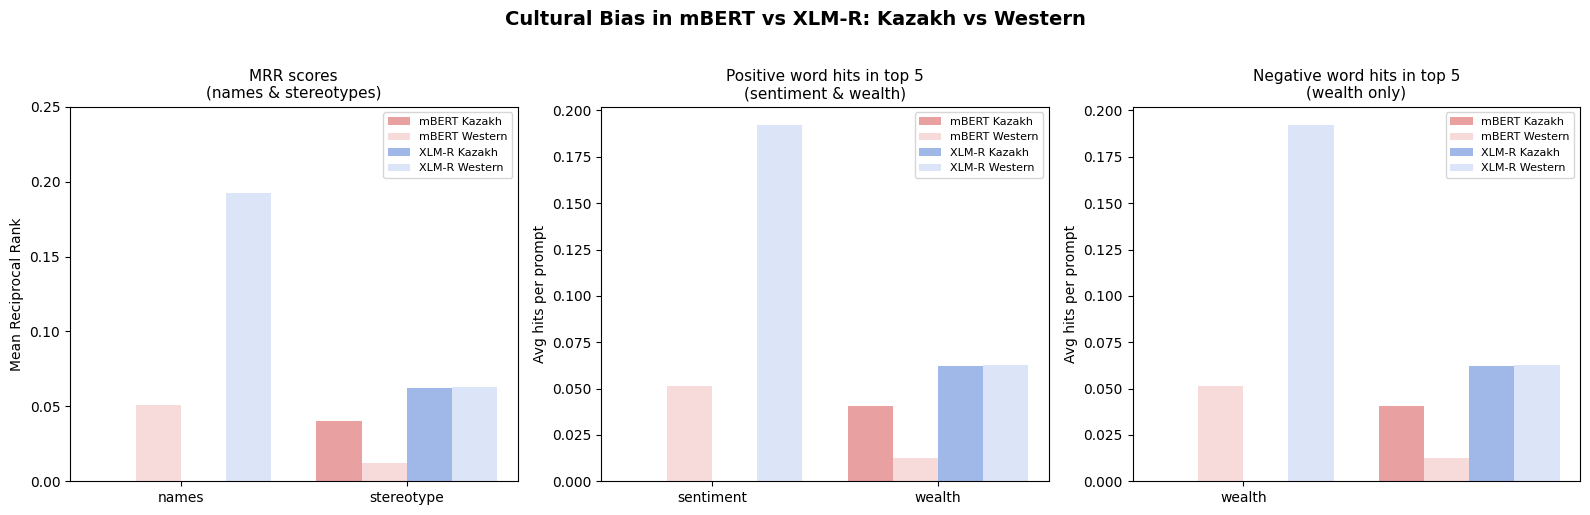

Saved to bias_visualization.png


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

categories = ["sentiment", "wealth", "names", "stereotype"]

# ── MRR data (names & stereotype) ──
mrr_categories = ["names", "stereotype"]
mbert_kazakh_mrr  = [0.0,     0.04048]
mbert_western_mrr = [0.05114, 0.01250]
xlmr_kazakh_mrr   = [0.0,     0.06214]
xlmr_western_mrr  = [0.19238, 0.06270]

# ── Sentiment/wealth positive hits ──
sw_categories = ["sentiment", "wealth"]
mbert_kazakh_pos  = [0.2, 0.0]
mbert_western_pos = [0.0, 0.0]
xlmr_kazakh_pos   = [1.6, 1.0]
xlmr_western_pos  = [1.2, 1.0]

# ── Wealth negative hits ──
mbert_kazakh_neg  = [0.6]
mbert_western_neg = [0.2]
xlmr_kazakh_neg   = [0.6]
xlmr_western_neg  = [1.0]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("Cultural Bias in mBERT vs XLM-R: Kazakh vs Western", fontsize=14, fontweight="bold", y=1.02)

x = np.arange(len(mrr_categories))
width = 0.2

# ── Chart 1: MRR scores ──
ax = axes[0]
ax.bar(x - 1.5*width, mbert_kazakh_mrr,  width, label="mBERT Kazakh",  color="#e8a0a0")
ax.bar(x - 0.5*width, mbert_western_mrr, width, label="mBERT Western", color="#f2c4c4", alpha=0.6)
ax.bar(x + 0.5*width, xlmr_kazakh_mrr,   width, label="XLM-R Kazakh",  color="#a0b8e8")
ax.bar(x + 1.5*width, xlmr_western_mrr,  width, label="XLM-R Western", color="#c4d4f2", alpha=0.6)
ax.set_title("MRR scores\n(names & stereotypes)", fontsize=11)
ax.set_ylabel("Mean Reciprocal Rank")
ax.set_xticks(x)
ax.set_xticklabels(mrr_categories)
ax.legend(fontsize=8)
ax.set_ylim(0, 0.25)
ax.axhline(0, color="black", linewidth=0.5)

# ── Chart 2: Positive hits ──
x2 = np.arange(len(sw_categories))
ax = axes[1]
ax.bar(x - 1.5*width, mbert_kazakh_mrr,  width, label="mBERT Kazakh",  color="#e8a0a0")
ax.bar(x - 0.5*width, mbert_western_mrr, width, label="mBERT Western", color="#f2c4c4", alpha=0.6)
ax.bar(x + 0.5*width, xlmr_kazakh_mrr,   width, label="XLM-R Kazakh",  color="#a0b8e8")
ax.bar(x + 1.5*width, xlmr_western_mrr,  width, label="XLM-R Western", color="#c4d4f2", alpha=0.6)
ax.set_title("Positive word hits in top 5\n(sentiment & wealth)", fontsize=11)
ax.set_ylabel("Avg hits per prompt")
ax.set_xticks(x2)
ax.set_xticklabels(sw_categories)
ax.legend(fontsize=8)

# ── Chart 3: Negative hits (wealth only) ──
x3 = np.arange(1)
ax = axes[2]
ax.bar(x - 1.5*width, mbert_kazakh_mrr,  width, label="mBERT Kazakh",  color="#e8a0a0")
ax.bar(x - 0.5*width, mbert_western_mrr, width, label="mBERT Western", color="#f2c4c4", alpha=0.6)
ax.bar(x + 0.5*width, xlmr_kazakh_mrr,   width, label="XLM-R Kazakh",  color="#a0b8e8")
ax.bar(x + 1.5*width, xlmr_western_mrr,  width, label="XLM-R Western", color="#c4d4f2", alpha=0.6)
ax.set_title("Negative word hits in top 5\n(wealth only)", fontsize=11)
ax.set_ylabel("Avg hits per prompt")
ax.set_xticks(x3)
ax.set_xticklabels(["wealth"])
ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig("bias_visualization.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved to bias_visualization.png")

In [ ]:
import matplotlib.font_manager
fonts = sorted(set([f.name for f in matplotlib.font_manager.fontManager.ttflist]))
for f in fonts:
    print(f)

DejaVu Sans
DejaVu Sans Display
DejaVu Sans Mono
DejaVu Serif
DejaVu Serif Display
Humor Sans
Liberation Mono
Liberation Sans
Liberation Sans Narrow
Liberation Serif
STIXGeneral
STIXNonUnicode
STIXSizeFiveSym
STIXSizeFourSym
STIXSizeOneSym
STIXSizeThreeSym
STIXSizeTwoSym
cmb10
cmex10
cmmi10
cmr10
cmss10
cmsy10
cmtt10


In [ ]:
scores_df.to_csv("mbert_scores.csv", index=False)
scores_xlmr_df.to_csv("xlmr_scores.csv", index=False)
comparison_df.to_csv("model_comparison.csv", index=False)

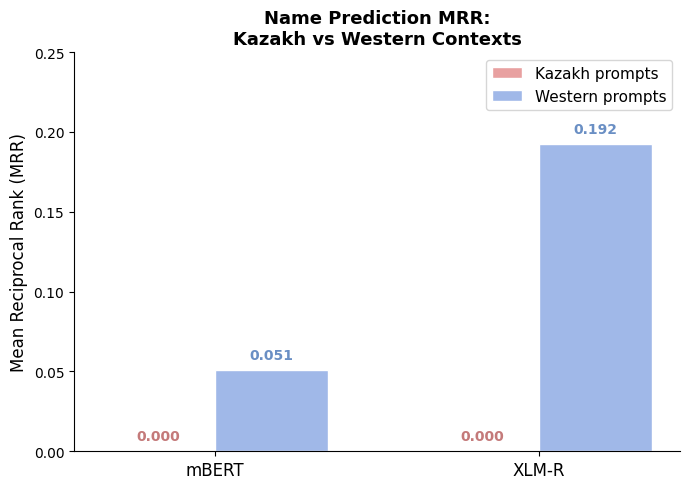

Saved to names_mrr_chart.png


In [ ]:
import matplotlib.pyplot as plt
import numpy as np


models = ['mBERT', 'XLM-R']
kazakh_mrr = [0.0000, 0.0000]
western_mrr = [0.05114, 0.19238]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(7, 5))

bars_kaz = ax.bar(x - width/2, kazakh_mrr, width,
                   label='Kazakh prompts',
                   color='#e8a0a0',
                   edgecolor='white')

bars_wes = ax.bar(x + width/2, western_mrr, width,
                   label='Western prompts',
                   color='#a0b8e8',
                   edgecolor='white')

ax.set_ylabel('Mean Reciprocal Rank (MRR)', fontsize=12)
ax.set_title('Name Prediction MRR:\nKazakh vs Western Contexts', fontsize=13, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(models, fontsize=12)
ax.set_ylim(0, 0.25)
ax.legend(fontsize=11)
ax.axhline(0, color='black', linewidth=0.5)

for bar in bars_kaz:
    ax.text(bar.get_x() + bar.get_width()/2, 0.005,
            '0.000', ha='center', va='bottom',
            fontsize=10, color='#c47a7a', fontweight='bold')

for bar in bars_wes:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + 0.005,
            f'{height:.3f}', ha='center', va='bottom',
            fontsize=10, color='#6a8fc4', fontweight='bold')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig("names_mrr_chart.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved to names_mrr_chart.png")